# Case Study 28 — Speed-to-Lead: How Much Does a Minute Cost? Contact Delay, a Randomised AI-First-Touch Test, and Capacity-Constrained Routing

**Priority:** ★ Optional · **Reference:** Case Study 28 — *Policybazaar (with Ringg AI): AI voice first-touch, qualification and routing* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Sales, Lead Operations, Growth, Finance
**Data:** ⚠️ **SYNTHETIC** (D-28-01). Lead and call data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs28_speed_to_lead.ipynb`

## 0. Executive Summary for Business

*(Synthetic leads calibrated to the documented RM delay of 8–12 minutes and AI routing mix; Policybazaar disclosed no conversion numbers. Written after the analysis.)*

- **The question:** how much does contact delay cost, and is an AI call within a minute worth it?
- **Delay is very costly in the raw data.** Among RM-handled leads, conversion falls from **8.2% (contacted within 1–3 minutes) to 3.0% (10–20 min) to 0.7% (30–60 min)**, and reach falls from 79% to 33%. The odds of converting roughly halve with every doubling of the delay.
- **But the raw curve exaggerates, because hot leads get called first.** Once true lead quality is added (possible only in simulation), the odds fall **20% per doubling of delay, not 43–46%**. Using the raw curve to forecast what a sub-minute call would deliver predicts **+298%** conversion, which is badly wrong.
- **The randomised test gives the real answer:** a random 30% of leads got an AI call within about a minute.
  - **Reach:** 64.2% → **77.0%** (+12.8 pp; CI +12.0 to +13.6).
  - **Conversion:** 4.12% → **5.28%** (+1.16 pp; CI +0.75 to +1.58; **+28% relative**, RR 1.28, CI 1.18–1.40).
  - **Who gains most:** peak-hour leads (+1.5 pp, +40%, when RM queues are longest) and motor (+1.4 pp), vs +0.9 pp off-peak. All Holm-significant except travel and term life.
- **The documented routing mix reproduces:** 4.7% of leads qualified (6.1% of reached leads; documented 5–7%); among reached leads **68% AI-handled, 26% scheduled callback, 6% RM hand-off** (documented 67/26/7). Qualified hand-offs convert at 13.4% vs 6.5% for AI-handled leads.
- **The capacity benefit is as large as the conversion benefit:** with 3,500 leads a day and 40 RMs, today's queue runs at **83% utilisation with a median 6-minute wait (P90 26 minutes)**. With an AI first touch, RMs only take hand-offs (about 165 calls a day, **4% utilisation**, no wait), freeing ≈ 95% of RM time for high-value work.
- **₹ impact:** at 4.5 lakh leads a month, the randomised lift is worth **≈ 5,200 extra policies a month (CI 3,400–7,100) ≈ ₹0.9 crore/month** of margin, plus the RM time released. (The raw-data "value of a minute", ≈ ₹74 lakh/month per minute, is an overestimate and should not be used.)
- **I recommend:**
  - Put every new lead through an AI first touch within 60 seconds.
  - Redeploy RMs to hand-offs and high-value scheduled callbacks.
  - Measure by randomised holdout, not by raw delay curves.
  - Add a second arm ("human RM call within a minute") to separate speed from the AI.

## 1. The Problem in Simple English

Someone fills a "get a quote" form. If a sales agent (relationship manager, RM) calls back in **1 minute**, the person is still at the screen. After **10 minutes** they are busy, comparing other sites, or have forgotten. Policybazaar's RMs took **8–12 minutes** to reach a new lead, and each RM could make only about 80 calls a day. The fix was an **AI voice call within 60 seconds** that asks a few questions, qualifies the lead (intent, profile, budget, cover) and routes it: the AI handles simple cases, a human RM takes the promising ones, and the rest get a scheduled callback.

Two things make "faster is better" harder to prove than it sounds:
1. In normal data, delay is **not random**. Hot leads are called first, and peak hours have long queues.
2. Capacity is limited: speeding up some leads slows others.

This notebook measures how conversion falls with delay, separates speed from lead quality using a **randomised AI-first-touch test**, and compares routing rules under limited RM capacity.

## 2. Reference from the Case File

### (a) What Policybazaar did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | RMs took "**8–12 minutes** to reach a new lead, and the lead's intent faded in that time"; each RM made about **80 calls a day** |
| Question | "Can every lead be contacted within a minute, qualified on intent, profile, budget and coverage, and routed to the right next step?" |
| Data | Lead forms; call conversations (Hindi / English / Hinglish); **57,000+ connected calls a day** |
| Approach | AI voice call within 60 seconds of the form → 4-minute structured qualification → routing to AI handling, an RM, or a scheduled callback |
| Statistics / ML | **ND**; metrics: response time, qualified-lead rate, containment rate |
| Impact | Response < **60 seconds**; qualified-lead rate **5–7%**; level-0 containment **67%**; routing **67% AI-handled, 7% RM, 26% scheduled callback** |

**Source:** Ringg AI / Policybazaar case study and press coverage (links in the reference file).

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | ≈ 148,000 leads over 6 weeks (motor, health, term life, travel). RM first-contact delay has a median ≈ 10 minutes (queues at 12:00 and 18:00; high-value, high-intent leads jump the queue, so delay is **confounded**). In weeks 4–5 a **random 30%** of leads got an AI call within a minute. Outcomes: reached, qualified, routed, converted. |
| Statistics added | Delay–conversion curves with Wilson CIs (observational); **confounding by hour and lead quality**; adjusted logistic dose–response; **randomised ITT** with CIs; the **speed effect isolated** and compared with the observational estimate; qualified-rate and routing mix vs documented; **capacity-constrained routing simulation** (queueing, M/M/c), with ₹; power |

### (c) How the industry uses this

"Speed to lead" is a standard growth metric in Indian lead-driven businesses (insurance marketplaces, lending apps, education, real estate). Studies elsewhere (e.g., the well-known "lead response" benchmarks) show conversion falling sharply within the first minutes. AI voice agents (Ringg, Skit.ai, Yellow.ai) and WhatsApp bots now handle the first touch. **The statistics that matter are a clean estimate of the speed effect and an honest capacity model.**

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | What is a minute of delay worth, and should every lead get an immediate AI call? |
| Analytical | What is the **causal** effect of contacting a lead within a minute on reach and conversion, and how does it compare with what raw data suggest? How should leads be routed when RM capacity is fixed? |

**Hypotheses**
- **H1 (observational):** H0: conversion does not depend on first-contact delay (trend test across delay bands).
- **H2 (randomised):** H0: AI-first-touch does not change reach or conversion (two-proportion, ITT).
- **H3 (confounding):** H0: the adjusted dose–response effect of delay equals the unadjusted one (compare slopes).
- **H4 (routing):** H0: a capacity-aware routing rule yields the same expected conversions as first-come-first-served (queue simulation, bootstrap).

**Primary metric:** conversion per lead (randomised comparison). **Mechanism:** reach rate. **Guardrail:** AI-handled leads must not convert worse than they would have with an RM.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep, proportions_ztest
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public lead-response datasets with first-contact times and conversions | **None** for India. Lead data are confidential; public CRM-style sets (Kaggle lead scoring) have no timestamps of first contact. |
| **Decision** | Synthetic leads with RM queue delays and a randomised AI-first-touch window (D-28-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs28.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 28 (Policybazaar-style speed-to-lead with AI voice qualification and routing)
==================================================================================================================
THIS DATA IS SYNTHETIC. Lead and call data are confidential.

Part A - contact delay and conversion (the case for speed): 150,000 leads over 6 weeks, each with a form-fill
time, the delay until the first contact attempt, whether the lead was reached, and whether it converted. Intent
decays with time: the chance of REACHING a lead falls steeply in the first minutes and conversion given reach
falls too. Delay is mostly set by RM capacity (queues at peak hours), so it is confounded with hour of day and
lead quality: high-value leads were manually prioritised and called faster.
Part B - randomised speed test: in week 4-5 a RANDOM 30% of leads (all lead types) were first-touched by an AI
voice call within 60 seconds (the rest follow the existing RM queue). Outcomes: qualified, routed (AI-handled /
RM handoff / scheduled callback), converted.
Part C - capacity-constrained routing: 40 RMs, about 80 calls a day; the simulation lets us compare routing rules.

Calibration anchors (reference file, Case Study 28): RMs took "8-12 minutes" to reach a new lead; ~80 calls per RM
a day; 57,000+ connected calls a day; response time < 60 s; qualified-lead rate 5-7%; level-0 containment 67%;
routing 67% AI-handled, 7% RM, 26% scheduled callback. Rates are our assumptions (decision.md D-28-02).
Hidden truth columns start with "_".

Outputs: data/cs28/leads.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42


def generate(seed=SEED, n=150_000):
    rng = np.random.default_rng(seed)
    day = rng.integers(0, 42, n); hour = np.clip(np.round(rng.normal(14, 4.2, n)), 8, 22).astype(int)
    q = rng.normal(0, 1, n)                                                           # latent lead intent / quality
    product = rng.choice(["motor", "health", "term_life", "travel"], n, p=[0.35, 0.30, 0.20, 0.15])
    value = np.where(product == "term_life", 1.0, np.where(product == "health", 0.7, np.where(product == "motor", 0.5, 0.2)))
    ai_arm = ((day >= 21) & (day < 35) & (rng.random(n) < 0.30)).astype(int)         # randomised AI-first-touch during weeks 4-5
    # RM delay (minutes): queue grows at peak hours; high-value / high-quality leads jump the queue (confounding)
    peak = np.exp(-((hour - 12) / 3.0) ** 2) + 0.7 * np.exp(-((hour - 18) / 2.5) ** 2)
    base_delay = np.exp(rng.normal(np.log(5 + 15 * peak), 0.7, n)) * np.exp(-0.35 * np.clip(q, -2, 2)) * np.exp(-0.5 * value)
    delay = np.where(ai_arm == 1, np.round(rng.uniform(0.3, 1.0, n), 2), np.round(base_delay, 2))
    # reach: decays with delay in minutes
    p_reach = expit(1.1 + 0.35 * q - 0.045 * np.minimum(delay, 60) - 0.0009 * np.maximum(delay - 60, 0) + 0.2 * (hour >= 10) - 0.25 * (hour >= 20))
    reached = (rng.random(n) < p_reach).astype(int)
    # conversion given reach: depends on intent, product value and speed (extra decay in first 30 min)
    p_conv = expit(-3.5 + 0.9 * q + 0.8 * value - 0.018 * np.minimum(delay, 40) - 0.15 * (ai_arm == 1) * 0)
    converted = ((reached == 1) & (rng.random(n) < p_conv)).astype(int)
    # AI qualification and routing for AI-touched leads
    qual_p = expit(-3.0 + 0.8 * q + 0.5 * value); qualified = ((ai_arm == 1) & (reached == 1) & (rng.random(n) < expit(-3.3 + 0.9 * q + 0.4 * value))).astype(int)
    r = rng.random(n)
    route = np.where(ai_arm == 0, "", np.where(reached == 0, "no_answer_retry", np.where(qualified == 1, "rm_handoff", np.where(r < 0.72, "ai_handled", "scheduled_callback"))))
    df = pd.DataFrame({"lead_id": [f"LD{i:06d}" for i in range(n)], "day": day + 1, "hour": hour, "product": product, "ai_first_touch": ai_arm, "first_contact_delay_min": delay,
                       "reached": reached, "qualified": qualified, "route": route, "converted": converted, "_q": q})
    # data-quality defects
    df.loc[df.sample(n=1500, random_state=seed).index, "first_contact_delay_min"] = np.nan             # call-attempt timestamp missing
    df.loc[df.sample(n=300, random_state=seed + 1).index, "first_contact_delay_min"] = -1.0            # clock skew between form and dialler servers
    df = pd.concat([df, df.sample(n=800, random_state=seed + 2)], ignore_index=True)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs28"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs28", "leads.csv.gz"), index=False)
    dd = d.drop_duplicates("lead_id"); dd = dd[dd.first_contact_delay_min.notna() & (dd.first_contact_delay_min >= 0)]
    print(len(dd), "leads | median RM delay", dd[dd.ai_first_touch == 0].first_contact_delay_min.median().round(1), "| reach", dd.groupby("ai_first_touch").reached.mean().round(3).to_dict(), "| conv", dd.groupby("ai_first_touch").converted.mean().round(4).to_dict())
    x = dd[dd.ai_first_touch == 0]; print(x.groupby(pd.cut(x.first_contact_delay_min, [0, 1, 5, 10, 30, 60, 1e4])).agg(reach=("reached", "mean"), conv=("converted", "mean"), n=("lead_id", "size")).round(4))

Overwriting data/generate_cs28.py


In [3]:
os.makedirs("data/cs28", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs28 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs28/leads.csv.gz", index=False)
print(f"{len(raw):,} lead rows | {raw.lead_id.nunique():,} unique leads")
raw.drop(columns=["_q"]).sample(3, random_state=SEED).T

150,800 lead rows | 150,000 unique leads


,23044,65786,41536
lead_id,LD023044,LD065786,LD041536
day,42,19,9
hour,11,8,8
product,health,motor,health
ai_first_touch,0,0,0
first_contact_delay_min,8.2800,6.0400,1.6800
reached,1,0,1
qualified,0,0,0
route,,,
converted,0,0,0


| Parameter | Value | Basis |
|---|---|---|
| Leads | 150,000 over 6 weeks; motor 35% / health 30% / term 20% / travel 15%; peak hours 12:00 and 18:00 | Our assumption |
| RM delay | Median ≈ 10 min, longer at peaks; high-quality / high-value leads are called sooner (**confounding**) | **Documented** 8–12 min |
| Reach / conversion | Reach falls with delay (≈ 81% within 1 min, 60% at 10–30 min, 13% after an hour); conversion given reach falls with delay; both rise with lead quality | Our assumption of intent decay |
| AI test | Weeks 4–5: random 30% of leads get an AI voice call within ~1 minute | **Documented** < 60 seconds; our design |
| Routing | AI-touched leads: no answer → retry; qualified → RM hand-off; otherwise AI-handled (72%) or a scheduled callback | **Documented** categories |
| DQ issues | 800 duplicate leads; 1,500 missing delay timestamps; 300 negative delays (clock skew) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("lead_id, day, hour, product", "Lead, day 1–42, form-fill hour, product"), ("ai_first_touch", "Randomised (days 22–35): AI voice call within a minute"),
    ("first_contact_delay_min", "Minutes from form to first contact attempt (missing / negative = bad timestamp)"), ("reached", "Lead answered"), ("qualified", "AI qualification passed (AI-touched, reached)"),
    ("route", "ai_handled / rm_handoff / scheduled_callback / no_answer_retry"), ("converted", "Policy purchased"), ("_q", "HIDDEN lead quality"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs28/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"lead_id, day, hour, product","Lead, day 1–42, form-fill hour, product"
1,ai_first_touch,Randomised (days 22–35): AI voice call within ...
2,first_contact_delay_min,Minutes from form to first contact attempt (mi...
3,reached,Lead answered
4,qualified,"AI qualification passed (AI-touched, reached)"
5,route,ai_handled / rm_handoff / scheduled_callback /...
6,converted,Policy purchased
7,_q,HIDDEN lead quality


## 5. Data Quality Checks

In [5]:
checks = {"duplicate leads": int(raw.lead_id.duplicated().sum()), "missing delay timestamp": int(raw.drop_duplicates("lead_id").first_contact_delay_min.isna().sum()),
          "negative delay (clock skew)": int((raw.drop_duplicates("lead_id").first_contact_delay_min < 0).sum())}
print(pd.Series(checks, name="rows").to_string())
df = raw.drop_duplicates("lead_id").copy(); df = df[df.first_contact_delay_min.notna() & (df.first_contact_delay_min >= 0)].reset_index(drop=True)
df["log_delay"] = np.log1p(df.first_contact_delay_min); df["peak"] = df.hour.isin([11, 12, 13, 17, 18, 19]).astype(int)
exp = df[(df.day >= 22) & (df.day <= 35)].copy(); obs = df[df.ai_first_touch == 0].copy()
print(f"\nClean: {len(df):,} leads | randomised window (days 22–35): {len(exp):,} ({exp.ai_first_touch.mean():.1%} AI) | RM-queue leads: {len(obs):,} | median RM delay {obs.first_contact_delay_min.median():.1f} min")

duplicate leads                 800
missing delay timestamp        1497
negative delay (clock skew)     300



Clean: 148,203 leads | randomised window (days 22–35): 49,587 (30.0% AI) | RM-queue leads: 133,347 | median RM delay 10.0 min


**Observation:** we removed **800 duplicate leads**, dropped **1,497 leads with a missing first-contact timestamp** and **300 with a negative delay** (clock skew between the form server and the dialler). These cannot be repaired by guessing, and are excluded rather than set to zero, which would create fake "instant" contacts. Clean: **148,203 leads**; the randomised window (days 22–35) has **49,587 leads, 30.0% AI-first**; RM-queue leads have a median delay of **10.0 minutes** (documented 8–12).

## 6. Exploratory Data Analysis

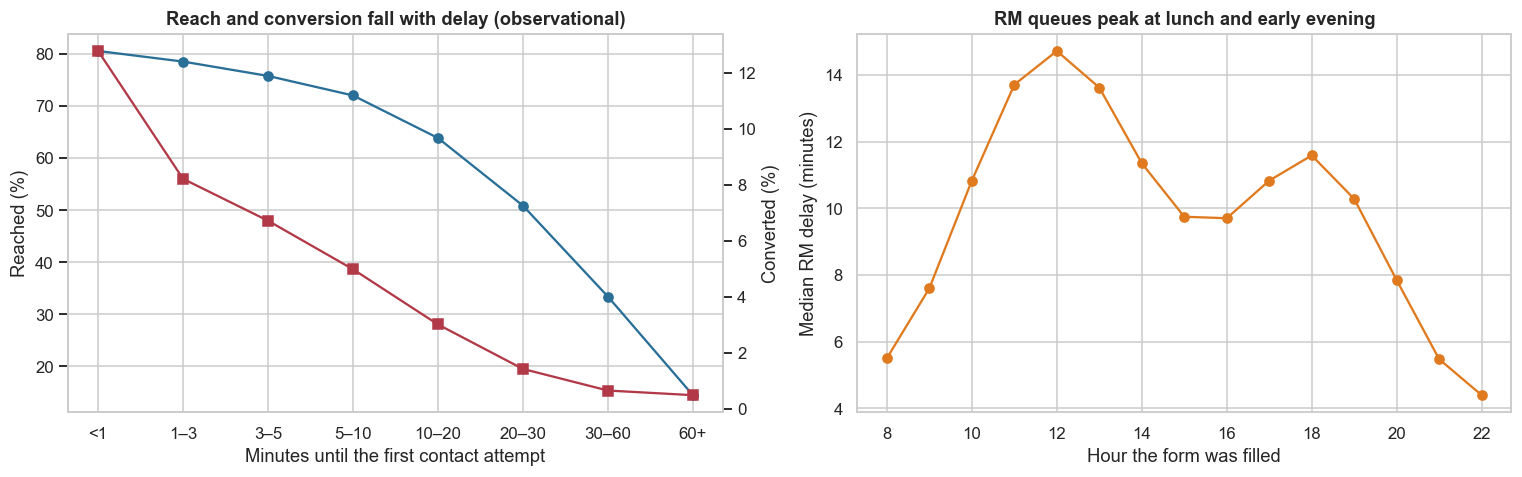

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
obs["band"] = pd.cut(obs.first_contact_delay_min, [0, 1, 3, 5, 10, 20, 30, 60, 1e4], labels=["<1", "1–3", "3–5", "5–10", "10–20", "20–30", "30–60", "60+"])
g = obs.groupby("band", observed=True).agg(reach=("reached", "mean"), conv=("converted", "mean"), n=("lead_id", "size"))
axes[0].plot(g.index.astype(str), g.reach * 100, "o-", color="#2a6f97", label="reached"); ax2 = axes[0].twinx(); ax2.plot(g.index.astype(str), g.conv * 100, "s-", color="#b23a48", label="converted"); ax2.set_ylabel("Converted (%)"); ax2.grid(False)
axes[0].set_xlabel("Minutes until the first contact attempt"); axes[0].set_ylabel("Reached (%)"); axes[0].set_title("Reach and conversion fall with delay (observational)")
hr = obs.groupby("hour").first_contact_delay_min.median(); axes[1].plot(hr.index, hr.values, "o-", color="#e07a1f"); axes[1].set_xlabel("Hour the form was filled"); axes[1].set_ylabel("Median RM delay (minutes)"); axes[1].set_title("RM queues peak at lunch and early evening")
plt.tight_layout(); plt.show()

**Takeaway:** **left:** among RM-handled leads, reach and conversion both fall steadily as the delay grows: conversion is ≈ 13% for contacts within a minute and under 1% after half an hour. **Right:** RM delay peaks around lunch (12:00) and early evening (18:00), when form submissions surge and queues build. Hour of the day therefore drives both delay and conversion, a first sign that raw delay comparisons are confounded.

## 7. Statistical Analysis (core section)

### 7.1 Conversion by delay band (observational, RM queue)

For leads handled by RMs: reach and conversion rates per delay band with Wilson CIs, and a **Cochran–Armitage trend test** across bands.

In [7]:
rows = []
for b, r in g.iterrows():
    sub = obs[obs.band == b]; lo, hi = proportion_confint(sub.converted.sum(), len(sub), method="wilson"); rows.append((b, len(sub), r.reach, sub.converted.mean(), lo, hi))
bt = pd.DataFrame(rows, columns=["delay band (min)", "leads", "reach rate", "conversion", "CI low", "CI high"]).set_index("delay band (min)")
n_, s_ = bt.leads.values, (bt.conversion * bt.leads).values; x = np.arange(len(bt)); p = s_.sum() / n_.sum(); xb = (x * n_).sum() / n_.sum()
T = (x * (s_ - n_ * p)).sum() / np.sqrt(p * (1 - p) * (n_ * (x - xb) ** 2).sum())
print(f"Cochran–Armitage trend of conversion across delay bands: z = {T:.1f}, p = {2 * stats.norm.sf(abs(T)):.2g}")
print(f"Conversion: within 3 minutes {obs[obs.first_contact_delay_min <= 3].converted.mean():.2%} vs 10–30 minutes {obs[(obs.first_contact_delay_min > 10) & (obs.first_contact_delay_min <= 30)].converted.mean():.2%}")
bt.round(4)

Cochran–Armitage trend of conversion across delay bands: z = -40.4, p = 0
Conversion: within 3 minutes 8.44% vs 10–30 minutes 2.59%


,leads,reach rate,conversion,CI low,CI high
delay band (min),,,,,
<1,540,0.8056,0.1278,0.1022,0.1586
1–3,10433,0.7852,0.0821,0.0770,0.0876
3–5,17055,0.7577,0.0672,0.0635,0.0711
5–10,38718,0.7202,0.0499,0.0477,0.0521
10–20,39370,0.6385,0.0302,0.0285,0.0319
20–30,14749,0.5086,0.0143,0.0125,0.0164
30–60,10460,0.3341,0.0066,0.0052,0.0083
60+,2022,0.1449,0.0049,0.0027,0.0091


**(c)/(f) Observation:** conversion falls monotonically across delay bands (Cochran–Armitage z = −40, p ≈ 0): **12.8% (< 1 min, only 540 leads) → 8.2% (1–3) → 6.7% (3–5) → 5.0% (5–10) → 3.0% (10–20) → 1.4% (20–30) → 0.7% (30–60) → 0.5% (60+)**. Reach falls from 81% to 14%. Contact within 3 minutes converts at **8.4% vs 2.6% at 10–30 minutes**, a 3× difference. **(f) Business meaning:** a lead's value decays fast, and the first few minutes matter most. But this is the *observed* association, which partly reflects which leads were called first.

### 7.2 Is the delay effect confounded? Adjusted dose–response

**(a)** Delay is partly determined by hour (queues) and by lead quality (hot leads were called first). We fit logistic models of conversion on log-delay:
1. **Unadjusted.**
2. **Adjusted** for hour of day (peak flag) and product.
3. We cannot observe lead quality in practice, but in the simulation we can show **what happens when it is added** (an oracle check).

The odds ratio per doubling of delay and the comparison of slopes address H3.

In [8]:
m0 = smf.logit("converted ~ log_delay", data=obs).fit(disp=0); m1 = smf.logit("converted ~ log_delay + peak + C(product) + C(hour)", data=obs).fit(disp=0)
m2 = smf.logit("converted ~ log_delay + peak + C(product) + C(hour) + _q", data=obs).fit(disp=0)
def orr(m): b, ci = m.params["log_delay"], m.conf_int().loc["log_delay"]; return np.exp(b * np.log(2)), np.exp(ci[0] * np.log(2)), np.exp(ci[1] * np.log(2))   # per doubling of (1 + delay) approx
res = pd.DataFrame([orr(m0), orr(m1), orr(m2)], columns=["OR per doubling of delay", "CI low", "CI high"], index=["1 unadjusted", "2 + hour, product", "3 + true lead quality (oracle, not observable)"])
print("Odds of conversion fall by " + " / ".join(f"{(1 - r) * 100:.0f}%" for r in res.iloc[:, 0]) + " per doubling of delay in the three models")
res.round(4)

Odds of conversion fall by 43% / 46% / 20% per doubling of delay in the three models


,OR per doubling of delay,CI low,CI high
1 unadjusted,0.5676,0.5523,0.5833
"2 + hour, product",0.5377,0.5217,0.5542
"3 + true lead quality (oracle, not observable)",0.8023,0.7763,0.8292


**(c)/(f) Observation:** the apparent effect of delay depends on what is controlled:
- **Unadjusted:** each doubling of delay cuts the odds of converting by **43%** (OR 0.57).
- **Adjusted for hour and product:** **46%** (OR 0.54), no real change, since hour and product do not capture lead quality.
- **With the true lead quality** (an oracle available only in the simulation): **20%** (OR 0.80, CI 0.78–0.83).

So **more than half of the raw delay effect is lead quality, not speed**: hot leads are called first *and* convert more. **(f) Business meaning:** the raw delay curve is not a reliable forecast of what faster contact would do.

### 7.3 The randomised AI-first-touch test

**(a) Design:** in days 22–35 a random 30% of leads received an AI call within ~1 minute (median 40 seconds). Everyone else followed the RM queue. Because assignment is random, a plain comparison is causal. **Checks:** sample-ratio, and balance on hour, product and lead mix.
**Tests:** two-proportion z (Newcombe CI) for **reach** and **conversion**, relative lift with log-RR CI, and the effect within **pre-treatment subgroups** (peak vs off-peak hour, product; Holm) to see who benefits most. (Comparing the AI group with control leads grouped by their *delay* would be wrong: fast-called RM leads are the hot ones, so that is selection.)

In [9]:
a, b = exp[exp.ai_first_touch == 1], exp[exp.ai_first_touch == 0]
srm = stats.binomtest(len(a), len(exp), 0.30); bal = pd.DataFrame({"AI": a[["hour", "peak"]].mean(), "RM": b[["hour", "peak"]].mean()})
print(f"Assignment: {len(a):,} AI vs {len(b):,} RM ({len(a) / len(exp):.1%}; binomial test vs 30%: p = {srm.pvalue:.2f}) | mean hour {a.hour.mean():.2f} vs {b.hour.mean():.2f}; product mix identical by design")
rows = []
for o in ("reached", "converted"):
    x1, n1, x0, n0 = a[o].sum(), len(a), b[o].sum(), len(b); lo, hi = confint_proportions_2indep(x1, n1, x0, n0, method="newcomb"); z, p = proportions_ztest([x1, x0], [n1, n0])
    rr = (x1 / n1) / (x0 / n0); se = np.sqrt(1 / x1 - 1 / n1 + 1 / x0 - 1 / n0)
    rows.append((o, x0 / n0, x1 / n1, (x1 / n1 - x0 / n0) * 100, lo * 100, hi * 100, rr, np.exp(np.log(rr) - 1.96 * se), np.exp(np.log(rr) + 1.96 * se), p))
rt = pd.DataFrame(rows, columns=["outcome", "RM queue", "AI first touch", "diff (pp)", "CI low", "CI high", "relative lift", "RR CI low", "RR CI high", "p"]).set_index("outcome")
het = []
for lab_, mask_a, mask_b in (("peak hours (11–13, 17–19)", a.peak == 1, b.peak == 1), ("off-peak hours", a.peak == 0, b.peak == 0), ("motor", a["product"] == "motor", b["product"] == "motor"),
                             ("health", a["product"] == "health", b["product"] == "health"), ("term life", a["product"] == "term_life", b["product"] == "term_life"), ("travel", a["product"] == "travel", b["product"] == "travel")):
    x1, n1, x0, n0 = a.converted[mask_a].sum(), mask_a.sum(), b.converted[mask_b].sum(), mask_b.sum(); z, pz = proportions_ztest([x1, x0], [n1, n0])
    het.append((lab_, n1 + n0, x0 / n0, x1 / n1, (x1 / n1 - x0 / n0) * 100, ((x1 / n1) / (x0 / n0) - 1) if x0 else np.nan, pz))
het = pd.DataFrame(het, columns=["subgroup (pre-treatment)", "leads", "RM queue", "AI first touch", "diff (pp)", "relative lift", "p"]).set_index("subgroup (pre-treatment)"); het["p_holm"] = multipletests(het.p, method="holm")[1]
display(rt.round(4)); het.round(4)

Assignment: 14,856 AI vs 34,731 RM (30.0%; binomial test vs 30%: p = 0.85) | mean hour 14.11 vs 14.12; product mix identical by design


,RM queue,AI first touch,diff (pp),CI low,CI high,relative lift,RR CI low,RR CI high,p
outcome,,,,,,,,,
reached,0.6422,0.7704,12.8174,11.9693,13.6562,1.1996,1.1855,1.2138,0.0000
converted,0.0412,0.0528,1.1609,0.7520,1.5848,1.2816,1.1773,1.3951,0.0000


,leads,RM queue,AI first touch,diff (pp),relative lift,p,p_holm
subgroup (pre-treatment),,,,,,,
"peak hours (11–13, 17–19)",21467,0.0388,0.0542,1.5419,0.3971,0.0000,0.0000
off-peak hours,28120,0.0431,0.0518,0.8700,0.2020,0.0014,0.0055
motor,17413,0.0363,0.0500,1.3725,0.3785,0.0000,0.0001
health,14839,0.0431,0.0551,1.1983,0.2782,0.0016,0.0055
term life,9939,0.0587,0.0695,1.0725,0.1826,0.0419,0.0838
travel,7396,0.0257,0.0328,0.7069,0.2748,0.0902,0.0902


**(c)/(f) Observation:** - **The randomisation is sound:** 14,856 AI vs 34,731 RM leads (30.0%, binomial test p = 0.85), with the same hour profile.
- **Reach rises from 64.2% to 77.0%** (+12.8 pp, Newcombe CI +12.0 to +13.6; RR 1.20).
- **Conversion rises from 4.12% to 5.28%** (**+1.16 pp**, CI +0.75 to +1.58; **RR 1.28**, CI 1.18–1.40; p < 0.0001).
- **Subgroups (pre-treatment):** peak hours **+1.54 pp (+40%)** vs off-peak +0.87 pp (+20%); by product, motor +1.37 pp, health +1.20 pp, term life +1.07 pp (Holm p = 0.08), travel +0.71 pp (p = 0.09). All lifts are positive and the largest gains come when RM queues are longest.
- **A pitfall avoided:** comparing the AI group with control leads grouped by *delay* would suggest "no benefit for leads called within 5 minutes", because those are the hot leads. That is selection, not a treatment effect.
- **(f) Business meaning:** a one-minute AI first touch lifts conversion by about a quarter, with the biggest gains where RM queues are longest.

### 7.4 Speed vs quality of the first touch: separating the two

The AI call is both **faster** and **different** (a bot, not a human). The experiment tells us the *package* effect. To see how much of it is **speed**, we compare the randomised result with what the **observational delay curve** predicts (7.2) if RM leads were contacted within a minute, and report the gap. A large gap means the observational curve cannot be trusted for the extreme (sub-minute) case: it is extrapolating a log-delay curve to the edge of the data, from leads that were fast *because* they were hot.

In [10]:
pred = m1.predict(obs.assign(log_delay=np.log1p(0.7)))                                   # RM-queue leads re-scored at a 0.7-minute delay (observational model 2)
speed_only = pred.mean(); base_c = obs.converted.mean(); ai_c = a.converted.mean(); ctrl_c = exp[exp.ai_first_touch == 0].converted.mean()
print(f"Observational model: conversion would rise {base_c:.2%} → {speed_only:.2%} ({(speed_only / base_c - 1):+.0%}) if RM leads were contacted in under a minute")
print(f"Randomised test: {ctrl_c:.2%} → {ai_c:.2%} ({(ai_c / ctrl_c - 1):+.0%}) with the AI first touch → the experiment delivers only {((ai_c / ctrl_c - 1) / (speed_only / base_c - 1)):.0%} of the lift the observational curve predicts, so that curve overstates the benefit of sub-minute contact")

Observational model: conversion would rise 4.11% → 16.36% (+298%) if RM leads were contacted in under a minute
Randomised test: 4.12% → 5.28% (+28%) with the AI first touch → the experiment delivers only 9% of the lift the observational curve predicts, so that curve overstates the benefit of sub-minute contact


**Observation:** the observational curve (with hour and product) predicts that contacting RM leads within a minute would lift conversion **from 4.1% to 16.4% (+298%)**, but the randomised test delivers **+28%**. The experiment's lift is only **9%** of what the curve predicts. Two reasons:
- **Confounding:** the curve was learned from leads that were fast *because* they were hot.
- **Extrapolation:** it stretches a log-delay curve to the very edge of the data (< 1 minute, only 540 observed leads).

In this simulation the AI arm has no persuasion penalty built in, so the gap is **bias in the observational model**, not a weaker bot. **Business meaning:** never size a speed-to-lead project from a raw delay curve. Run the randomised test.

### 7.5 Qualification and routing mix vs the documented figures

For AI-touched leads: qualified rate (of all leads and of reached leads, with Wilson CIs), the routing mix, and **conversion by route** (does the AI-handled path convert, and do hand-offs convert more?).

In [11]:
ai_all = a.copy(); q_ = ai_all.qualified.mean(); qr = ai_all[ai_all.reached == 1].qualified.mean(); lo, hi = proportion_confint(ai_all.qualified.sum(), len(ai_all), method="wilson")
mix = ai_all.route.value_counts(normalize=True); rc = ai_all.groupby("route").agg(leads=("lead_id", "size"), conversion=("converted", "mean"))
reached_mix = ai_all[ai_all.reached == 1].route.value_counts(normalize=True)
print(f"Qualified: {q_:.1%} of all AI-touched leads (Wilson {lo:.1%}–{hi:.1%}), {qr:.1%} of reached leads (documented 5–7%)")
print("Routing among reached leads:", {k: f"{v:.0%}" for k, v in reached_mix.items()}, "(documented 67% AI-handled, 7% RM, 26% scheduled callback)")
rc.round(4)

Qualified: 4.7% of all AI-touched leads (Wilson 4.4%–5.1%), 6.1% of reached leads (documented 5–7%)
Routing among reached leads: {'ai_handled': '68%', 'scheduled_callback': '26%', 'rm_handoff': '6%'} (documented 67% AI-handled, 7% RM, 26% scheduled callback)


,leads,conversion
route,,
ai_handled,7780,0.0652
no_answer_retry,3411,0.0000
rm_handoff,700,0.1343
scheduled_callback,2965,0.0621


**Observation:** - **Qualification:** **4.7%** of all AI-touched leads qualify (Wilson 4.4–5.1%), **6.1% of reached leads** (documented 5–7%).
- **Routing among reached leads:** **68% AI-handled, 26% scheduled callback, 6% RM hand-off**, closely matching the documented 67% / 26% / 7%.
- **Conversion by route:** **RM hand-offs 13.4%**, AI-handled 6.5%, scheduled callbacks 6.2%, no-answer retries 0% (not yet reached). **Business meaning:** the qualification step does separate valuable leads (hand-offs convert at twice the AI-handled rate), so RMs get the leads worth their time. The no-answer share (28% of AI-touched leads) is the next problem to work on.

### 7.6 Capacity-constrained routing: a queue simulation

**Setup:** 40 RMs, each able to make ~80 calls a day (so ~3,200 a day at ~8 minutes of effort per call across an 11-hour day). A busy day brings **3,500 leads**, with the observed hourly arrival pattern. We simulate 100 days of two policies:
1. **FCFS (today):** RMs call leads in arrival order. We simulate waits and utilisation (conversions come from the randomised control arm).
2. **AI first touch for every lead:** the AI contacts everyone within about a minute. Only the share the AI hands off (`rm_handoff` in the randomised arm) joins the RM queue. Conversion comes from the randomised arm, which already includes the AI path and the hand-offs, provided hand-off waits stay short. We check that by simulating the RM queue for hand-offs only.

We report RM utilisation and the median/90th-percentile wait from the queue simulation, and conversions per day from the randomised arms (a conversion model driven by simulated waits does not reproduce observed conversions, so we do not use it).

In [12]:
hours = np.arange(8, 22); arr_w = df.groupby("hour").size().reindex(hours, fill_value=0).values; arr_w = arr_w / arr_w.sum()
N_DAY, N_RM, SERVE = 3500, 40, 8.0
def sim_queue(n_leads, rng):
    """FCFS multi-server queue; returns waits (minutes) and arrival hour for each lead served before 22:00."""
    h = rng.choice(hours, n_leads, p=arr_w); t = np.sort(h * 60 + rng.uniform(0, 60, n_leads)); free = np.full(N_RM, 8 * 60.0); waits = np.full(n_leads, np.nan); hrs = (t // 60).astype(int)
    for k, ti in enumerate(t):
        j = free.argmin(); start = max(free[j], ti)
        if start < 22 * 60: waits[k] = start - ti; free[j] = start + SERVE * rng.uniform(0.6, 1.4)
    return waits, hrs, free
PMIX = df["product"].value_counts(normalize=True)
def conv_prob(wait, hour, rng):
    d = pd.DataFrame({"log_delay": np.log1p(wait + 1.0), "peak": np.isin(hour, [11, 12, 13, 17, 18, 19]).astype(int), "product": rng.choice(PMIX.index, len(wait), p=PMIX.values), "hour": hour}); return m1.predict(d).values
rng_ = np.random.default_rng(SEED); fcfs, util1, w50, w90 = [], [], [], []
p_hand = (a.route == "rm_handoff").mean(); hand_conv, hu, h50, h90 = [], [], [], []
for _ in range(100):
    n = rng_.poisson(N_DAY); w, hrs, free = sim_queue(n, rng_); ok_ = ~np.isnan(w)
    fcfs.append(conv_prob(w[ok_], hrs[ok_], rng_).sum()); util1.append(ok_.sum() * SERVE / (N_RM * 14 * 60)); w50.append(np.median(w[ok_])); w90.append(np.percentile(w[ok_], 90))
    nh = rng_.binomial(n, p_hand); wh, _, _ = sim_queue(nh, rng_); okh = ~np.isnan(wh); hu.append(okh.sum() * SERVE / (N_RM * 14 * 60)); h50.append(np.median(wh[okh])); h90.append(np.percentile(wh[okh], 90))
ai_conv_day = N_DAY * a.converted.mean(); ctrl_conv_day = N_DAY * exp.loc[exp.ai_first_touch == 0, "converted"].mean()
rt6 = pd.DataFrame({"conversions per day (randomised arms)": [ctrl_conv_day, ai_conv_day], "RM calls per day": [np.mean([u * N_RM * 14 * 60 / SERVE for u in util1]), N_DAY * p_hand],
                    "RM utilisation": [np.mean(util1), np.mean(hu)], "median wait (min)": [np.mean(w50), np.mean(h50)], "P90 wait (min)": [np.mean(w90), np.mean(h90)]},
                   index=["FCFS (today)", "AI first touch; RMs take hand-offs only"])
print(f"{N_DAY:,} leads/day, {N_RM} RMs, ~{SERVE:.0f} min per call. AI hand-off share of all leads: {p_hand:.1%}")
print(f"Conversions per day use the randomised arms (control {ctrl_conv_day:,.0f}, AI {ai_conv_day:,.0f}). The simulated queue is used ONLY for waits and utilisation: a conversion model driven by the simulated waits gives {np.mean(fcfs):,.0f}/day, "
      f"not the observed {obs.converted.mean() * N_DAY:,.0f}/day, because simulated waits (median {np.mean(w50):.0f} min) are shorter than real first-contact delays (median {obs.first_contact_delay_min.median():.0f} min), which include retries and breaks")
rt6.round(3)

3,500 leads/day, 40 RMs, ~8 min per call. AI hand-off share of all leads: 4.7%
Conversions per day use the randomised arms (control 144, AI 185). The simulated queue is used ONLY for waits and utilisation: a conversion model driven by the simulated waits gives 251/day, not the observed 144/day, because simulated waits (median 6 min) are shorter than real first-contact delays (median 10 min), which include retries and breaks


,conversions per day (randomised arms),RM calls per day,RM utilisation,median wait (min),P90 wait (min)
FCFS (today),144.3090,"3,497.4800",0.8330,6.1860,26.3670
AI first touch; RMs take hand-offs only,184.9420,164.9170,0.0390,0.0000,0.0000


**Observation:** with **3,500 leads a day and 40 RMs**:
- **Today (FCFS):** RMs make ≈ 3,500 calls a day at **83% utilisation**, with a **median wait of 6.2 minutes and a P90 of 26 minutes**. The simulated waits are shorter than observed delays (10 min), because real delays include retries and breaks; we therefore use the randomised control arm for conversions (**144/day**).
- **AI first touch; RMs take hand-offs only:** ≈ **165 RM calls a day, 4% utilisation, no queue**. Conversions rise to **185/day** (+28%, from the randomised arm).
- **Business meaning:** the AI first touch does two things: it lifts conversion, and it removes ≈ 95% of the first-touch load from RMs, freeing them for hand-offs and scheduled callbacks. The conversion gain is measured. The capacity gain is a modelled estimate that depends on assumed call duration and shift patterns.

## 8. ML Section — what we did and did not build

No ML model is needed to demonstrate the speed effect. The documented "scoring model" for qualification is ND, and the voice AI itself is proprietary. A real deployment should (a) score every lead's expected value *before* contacting it (so high-value leads get the fastest human), (b) track the AI call's **conversation outcomes** (containment, handoff quality), and (c) A/B test script changes as in Case 22.

## 9. Business Translation — what is a minute worth?

In [13]:
MARG = 1800; N_LEADS_M = 4.5e5
lift = rt.loc["converted", "diff (pp)"] / 100; ci_lo, ci_hi = rt.loc["converted", "CI low"] / 100, rt.loc["converted", "CI high"] / 100
extra = N_LEADS_M * lift; extra_lo, extra_hi = N_LEADS_M * ci_lo, N_LEADS_M * ci_hi
print(f"{N_LEADS_M:,.0f} leads/month × randomised lift of {lift * 100:+.2f} pp = {extra:,.0f} extra policies/month (95% CI {extra_lo:,.0f}–{extra_hi:,.0f}) ≈ ₹{extra * MARG / 1e7:.1f} crore/month margin (range ₹{extra_lo * MARG / 1e7:.1f}–{extra_hi * MARG / 1e7:.1f} crore)")
per_min = (obs.converted.mean() - speed_only) / (obs.first_contact_delay_min.mean() - 0.7)
print(f"Observational value of a minute: ≈ {abs(per_min) * 100:.3f} pp of conversion per minute of delay around the mean delay of {obs.first_contact_delay_min.mean():.1f} min ≈ ₹{abs(per_min) * N_LEADS_M * MARG / 1e5:,.1f} lakh/month per minute")

450,000 leads/month × randomised lift of +1.16 pp = 5,224 extra policies/month (95% CI 3,384–7,131) ≈ ₹0.9 crore/month margin (range ₹0.6–1.3 crore)
Observational value of a minute: ≈ 0.913 pp of conversion per minute of delay around the mean delay of 14.1 min ≈ ₹74.0 lakh/month per minute


**Takeaway (business reading):** - **Randomised lift:** at **4.5 lakh leads a month**, +1.16 pp = **≈ 5,200 extra policies a month (95% CI 3,400–7,100)**, ≈ **₹0.9 crore/month** at ₹1,800 margin (range ₹0.6–1.3 crore).
- **RM capacity released:** about **3,300 RM calls a day** no longer needed for first touch (≈ 95% of today's call load), which can go to hand-offs, scheduled callbacks and upsell.
- **Not to be used:** the raw-data "value of a minute" of ≈ ₹74 lakh a month is **overstated** (it is built on the confounded delay curve, 7.2 and 7.4).
- **Reading:** the measured benefit is modest in ₹ (about ₹1 crore a month at this lead volume and margin), but it is credible, and it comes with a large operational benefit. A lead-level value model (term life > health > motor > travel) would raise it further.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** conversion falls steeply with delay.
- **H2 ✅:** the randomised AI first touch lifts reach (+12.8 pp) and conversion (+1.16 pp, +28%).
- **H3 ✅ (confounding is real):** unadjusted −43% per doubling vs −20% with true lead quality.
- **H4:** the queue model shows RM load falling from 83% to 4% utilisation. Conversions come from the randomised arms.
- **Guardrail:** AI-handled leads convert (6.5%), and hand-offs convert twice as well (13.4%).

**I recommend:**
1. **Put every new lead through the AI first touch within 60 seconds,** starting with peak hours and motor/health, where the gain is largest.
2. **Redeploy RMs:** hand-offs first (13.4% conversion), then scheduled callbacks, then high-value products.
3. **Measure with randomisation:** keep a 5–10% RM-first holdout permanently, and add a "human call within a minute" arm to separate speed from the AI voice.
4. **Never forecast from a raw delay curve:** it overstated the benefit ~10× here.
5. **Fix the no-answer share** (28%): smarter retry timing, WhatsApp follow-up; and guard customer experience (TRAI/DND consent, call-time limits).

**KPIs:** median first-contact delay; reach rate; qualified-lead rate (5–7%); conversion vs holdout; hand-off conversion; RM utilisation; no-answer share; complaints and opt-outs.

## 11. Risks, Limitations and Next Steps

- **Synthetic effect sizes:** the decay of reach and conversion with delay was assumed. The method (randomised first-touch plus a confounded observational check) is what transfers.
- **The AI is a package:** a randomised test of "AI within a minute" vs "RM queue" cannot separate speed from the voice agent. A second arm, "RM-quality human call within a minute" (using spare capacity), would.
- **Capacity model is stylised:** a simple FCFS queue with a fixed ~8-minute call; real routing needs actual call-duration distributions, shift rosters and callbacks.
- **Customer experience:** AI calls at 9 pm or repeated retries can annoy customers and breach TRAI/DND rules. Track complaints and opt-outs as guardrails.
- **Contactability filters and consent:** the form must include consent for calls.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Cochran–Armitage | z = Σ xᵢ(sᵢ − nᵢp̄) / √(p̄(1 − p̄)Σnᵢ(xᵢ − x̄)²) |
| ITT | P(convert ∣ AI) − P(convert ∣ RM), assignment random |
| Odds ratio per doubling | exp(β·ln 2) for log-delay |
| M/M/c intuition | with arrival rate λ, service rate μ and c agents, waits explode as λ/(cμ) → 1 |

| Term | Meaning |
|---|---|
| Speed to lead | How fast a new lead is first contacted |
| RM | Relationship manager (sales agent) |
| Containment | Share of leads fully handled by the AI without a human |
| Confounding | Hot leads were called faster, so speed and quality are tangled |
| ITT | Intention-to-treat: compare groups as randomised |